In [1]:
from pynq import Overlay
from pynq.lib.video import *
import numpy as np

base = Overlay("/home/xilinx/pynq/overlays/base/base.bit")
print("Base overlay 加载成功")

Base overlay 加载成功


In [2]:
from pynq import Overlay, allocate

sobel_ol = Overlay("/home/xilinx/jupyter_notebooks/pynq_sobel/system_wrapper1.bit")
dma = sobel_ol.axi_dma_0
sobel_ip = sobel_ol.sobel_filter_0
print("Sobel overlay 加载成功")

Sobel overlay 加载成功


In [3]:
from PIL import Image
import time

img = Image.open("/home/xilinx/jupyter_notebooks/pynq_sobel/input.png").convert("L").resize((640, 480))
in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
out_buf = allocate(shape=(480, 640), dtype=np.uint8)
in_buf[:] = np.array(img, dtype=np.uint8)

sobel_ip.write(0x10, 480)
sobel_ip.write(0x18, 640)

dma.recvchannel.transfer(out_buf)
dma.sendchannel.transfer(in_buf)
sobel_ip.write(0x00, 0x01)

for i in range(10):
    time.sleep(0.5)
    ctrl = sobel_ip.read(0x00)
    recv_idle = dma.recvchannel.idle
    send_idle = dma.sendchannel.idle
    print(f"t={i*0.5:.1f}s ap_ctrl=0x{ctrl:08X} recv_idle={recv_idle} send_idle={send_idle}")
    if recv_idle and send_idle:
        print("✅ 传输完成！")
        break

print("非零像素数:", np.count_nonzero(out_buf))

t=0.0s ap_ctrl=0x0000000E recv_idle=True send_idle=True
✅ 传输完成！
非零像素数: 272348


In [4]:
from PIL import Image

result_img = Image.fromarray(out_buf)
result_img.save("/home/xilinx/jupyter_notebooks/pynq_sobel/output_sobel.png")
print("结果已保存到 output_sobel.png")

结果已保存到 output_sobel.png


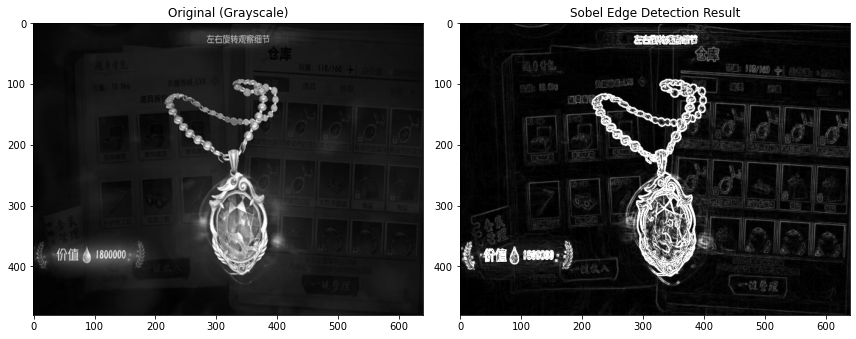

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(np.array(img), cmap='gray')
axes[0].set_title("Original (Grayscale)")
axes[1].imshow(out_buf, cmap='gray')
axes[1].set_title("Sobel Edge Detection Result")
plt.tight_layout()
plt.savefig("/home/xilinx/jupyter_notebooks/pynq_sobel/comparison.png", dpi=150)
plt.show()

In [6]:
from PIL import Image
import numpy as np
import time
from pynq import allocate

img = Image.open("/home/xilinx/jupyter_notebooks/pynq_sobel/input.png").convert("L").resize((640, 480))
src_np = np.array(img, dtype=np.uint8)

in_buf  = allocate(shape=(480, 640), dtype=np.uint8)
out_buf = allocate(shape=(480, 640), dtype=np.uint8)

N = 100  # 跑100次取平均
times_hw = []

for _ in range(N):
    in_buf[:] = src_np
    sobel_ip.write(0x10, 480)
    sobel_ip.write(0x18, 640)

    t0 = time.perf_counter()
    dma.recvchannel.transfer(out_buf)
    dma.sendchannel.transfer(in_buf)
    sobel_ip.write(0x00, 0x01)
    dma.recvchannel.wait()
    dma.sendchannel.wait()
    t1 = time.perf_counter()

    times_hw.append(t1 - t0)

hw_avg = np.mean(times_hw) * 1000  # 转换为毫秒
hw_fps = 1.0 / np.mean(times_hw)
print(f"硬件加速平均耗时: {hw_avg:.2f} ms")
print(f"硬件加速帧率: {hw_fps:.1f} FPS")

硬件加速平均耗时: 4.03 ms
硬件加速帧率: 248.3 FPS


In [7]:
import numpy as np
import time
from PIL import Image
from scipy.ndimage import convolve

img = Image.open("/home/xilinx/jupyter_notebooks/pynq_sobel/input.png").convert("L").resize((640, 480))
src_np = np.array(img, dtype=np.float32)

Kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
Ky = np.array([[-1,-2,-1], [ 0, 0, 0], [ 1, 2, 1]], dtype=np.float32)

N = 100
times_sw = []

for _ in range(N):
    t0 = time.perf_counter()
    gx = convolve(src_np, Kx)
    gy = convolve(src_np, Ky)
    mag = np.clip(np.abs(gx) + np.abs(gy), 0, 255).astype(np.uint8)
    t1 = time.perf_counter()
    times_sw.append(t1 - t0)

sw_avg = np.mean(times_sw) * 1000
sw_fps = 1.0 / np.mean(times_sw)
print(f"纯Python Sobel平均耗时: {sw_avg:.2f} ms")
print(f"纯Python Sobel帧率: {sw_fps:.1f} FPS")
print(f"\n加速比: {sw_avg/hw_avg:.1f}x")
print(f"帧率提升: {hw_fps/sw_fps:.1f}x")

纯Python Sobel平均耗时: 181.06 ms
纯Python Sobel帧率: 5.5 FPS

加速比: 45.0x
帧率提升: 45.0x
